## NB08 — Treinamento e Avaliação de Modelos

**Entrada:** `data/load/dataset_ml_model.csv` — 74.755 linhas × 27 colunas (gerado pelo NB07)

**Objetivo:** Treinar e avaliar o modelo de detecção de anomalias **Isolation Forest, LOF e One Class SVM** sobre o
dataset de propostas de licitações de Pernambuco (2020–2024).

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

os.makedirs('data/load', exist_ok=True)
print('Setup OK')

Setup OK


In [2]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('figuras_tcc', exist_ok=True)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['axes.unicode_minus'] = True

def br(x, casas=0):
    """12345.678 -> '12.345,7' (ponto no milhar, vírgula decimal, sinal de menos correto)."""
    s = f'{round(x, casas) + 0.0:,.{casas}f}'  # '+ 0.0' evita '-0,00'
    return s.replace(',', '#').replace('.', ',').replace('#', '.').replace('-', '\u2212')

def fmt_eixo(ax, eixo='y', casas=0, pct=False):
    """Formato brasileiro nos números de um eixo. pct=True: multiplica por 100 e acrescenta '%'."""
    if pct:
        f = FuncFormatter(lambda v, _: br(v * 100, casas) + '%')
    else:
        f = FuncFormatter(lambda v, _: br(v, casas))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)

In [3]:
df = pd.read_csv('data/load/dataset_ml_model.csv')

print(f'Shape: {df.shape}')
print(f'\nColunas ({len(df.columns)}):')
print(list(df.columns))
print('\nTipos de dados:')
print(df.dtypes)
df.head(3)

Shape: (74755, 27)

Colunas (27):
['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'idade_imputada', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']

Tipos de dados:
orgaoEntidadeCnpj                 int64
anoCompraPncp                     int64
sequencialCompraPncp              int64
numeroItem                        int64
cnpj_forn_norm                    int64
desvio_item_estimado            float64
n_propostas_item                  int64
fornecedor_unico                  int64
ano                               int64
mes                               int64
trimestre                   

,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,...,idade_empresa_anos,idade_imputada,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidade_Dispensa,modalidade_Inexigibilidade,modalidade_Licitacao,porte,descricao_situacao_cadastral
0,2030715000112,2023,1,1,44051659000142,-0.354518,1,1,2023,1,...,8.670773,1,0,0,0,1,0,0,0,0
1,2030715000112,2023,3,1,44051659000142,-0.019704,1,1,2023,1,...,8.670773,1,0,0,0,1,0,0,0,0
2,508903000188,2022,324,1,32212672000157,0.000000,1,1,2023,1,...,8.670773,1,0,0,0,1,0,0,0,0


---
### 1. Preparação: Remoção de Identificadores

In [4]:
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df = df.drop(identificadores, axis=1)

# Fixa as features aqui, antes de qualquer modelo: reexecutar células depois não pode incluir as saídas dos modelos
# (anomaly_score, anomaly...) como variáveis. Foi esse estado residual que gerou 763 sinalizados no LOF em vez de 755.
feature_cols = df.columns.tolist()
df

,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,trimestre,dia_semana,dias_desde_eleicao,pre_eleitoral_180d,pos_eleitoral_180d,...,idade_empresa_anos,idade_imputada,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidade_Dispensa,modalidade_Inexigibilidade,modalidade_Licitacao,porte,descricao_situacao_cadastral
0,-0.354518,1,1,2023,1,1,0,-636,0,0,...,8.670773,1,0,0,0,1,0,0,0,0
1,-0.019704,1,1,2023,1,1,1,-635,0,0,...,8.670773,1,0,0,0,1,0,0,0,0
2,0.000000,1,1,2023,1,1,4,-625,0,0,...,8.670773,1,0,0,0,1,0,0,0,0
3,-0.006719,1,1,2023,1,1,0,-636,0,0,...,8.670773,1,0,0,0,1,0,0,0,0
4,0.000000,1,1,2023,1,1,0,-622,0,0,...,8.670773,1,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74750,-0.000100,1,1,2024,12,4,2,73,0,1,...,8.670773,1,0,0,0,0,0,1,0,0
74751,-0.000100,1,1,2024,12,4,2,73,0,1,...,8.670773,1,0,0,0,0,0,1,0,0
74752,-0.000089,1,1,2024,12,4,2,73,0,1,...,8.670773,1,0,0,0,0,0,1,0,0
74753,-0.000092,1,1,2024,12,4,2,73,0,1,...,8.670773,1,0,0,0,0,0,1,0,0


---
### 2. Treinamento 

### Isolation Forest

O **Isolation Forest** detecta anomalias isolando observações com árvores de decisão aleatórias.
Pontos anômalos são isolados com menos cortes do que pontos normais, resultando em um
`anomaly_score` mais negativo.

**Hiperparâmetros:**

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `n_estimators` | 100 | Número de árvores — bom equilíbrio entre estabilidade e custo computacional |
| `contamination` | 0.01 | 1% de anomalias esperadas — conservador, alinhado com Araújo et al. (2024) |
| `max_samples` | 256 | Amostras por árvore — padrão do sklearn, eficiente em datasets grandes |
| `random_state` | 42 | Reprodutibilidade dos resultados |

In [5]:
# Train Isolation Forest
iso_forest = IsolationForest(n_estimators=100,
                            contamination=0.01, # Expected proportion of anomalies
                            max_samples=256, # Number of samples used to train each tree
                            random_state=42)
iso_forest.fit(df[feature_cols])

IsolationForest(contamination=0.01, max_samples=256, random_state=42)

In [6]:
# 1 = normal ; -1 anomalo
df['anomaly_score'] = iso_forest.decision_function(df[feature_cols])
df['anomaly'] = iso_forest.predict(df[feature_cols])
df['anomaly'].value_counts()

anomaly
 1    74008
-1      747
Name: count, dtype: int64

### Resultados e Visualizações - Isolation Forest

#### Gráfico de dispersão (score × índice)

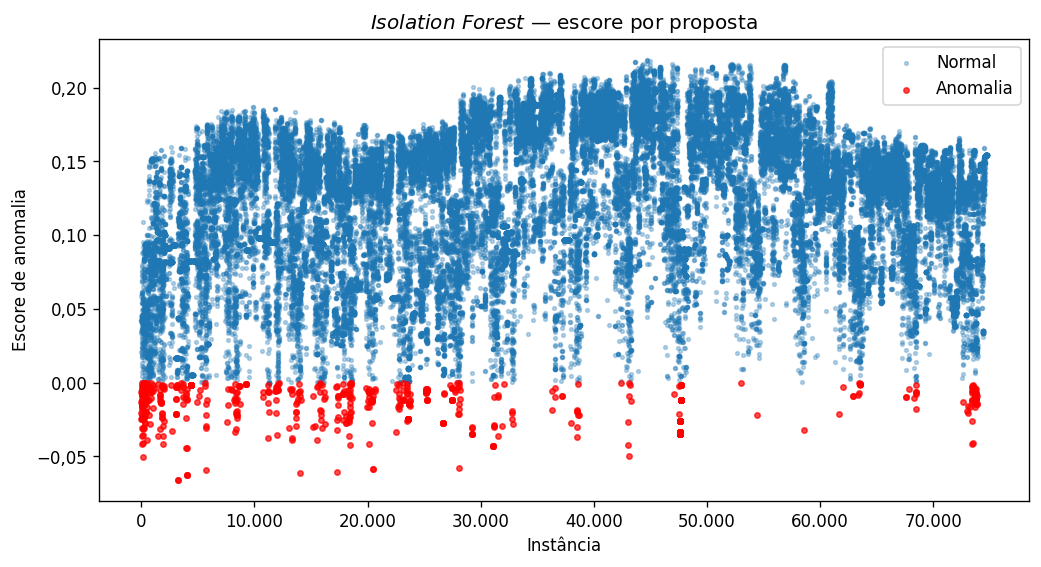

In [7]:
plt.figure(figsize=(10, 5))

normal = df[df['anomaly'] == 1]
plt.scatter(normal.index, normal['anomaly_score'], label='Normal', alpha=0.3, s=5)

anomalies = df[df['anomaly'] == -1]
plt.scatter(anomalies.index, anomalies['anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')

plt.xlabel("Instância")
plt.ylabel("Escore de anomalia")
plt.title(r'$\mathit{Isolation\ Forest}$ — escore por proposta')
plt.legend()
fmt_eixo(plt.gca(), 'x', 0)
fmt_eixo(plt.gca(), 'y', 2)
plt.savefig('figuras_tcc/image15.png', dpi=200, bbox_inches='tight')
plt.show()

#### Histograma de distribuição

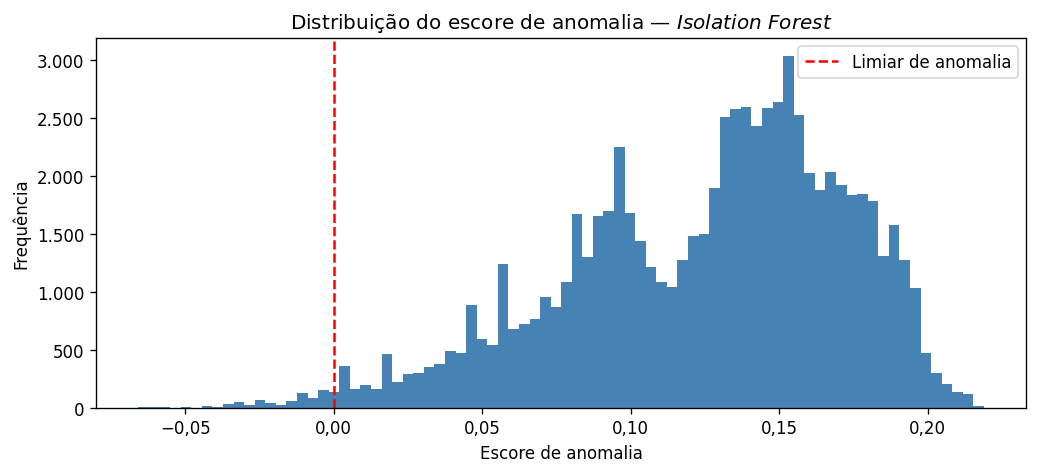

Total de anomalias detectadas: 747 (1.0%)


In [8]:
# Distribuição do anomaly_score
plt.figure(figsize=(10, 4))
plt.hist(df['anomaly_score'], bins=80, color='steelblue', edgecolor='none')
plt.axvline(df[df['anomaly'] == -1]['anomaly_score'].max(), color='red', linestyle='--', label='Limiar de anomalia')
plt.xlabel("Escore de anomalia")
plt.ylabel("Frequência")
plt.title(r'Distribuição do escore de anomalia — $\mathit{Isolation\ Forest}$')
plt.legend()
fmt_eixo(plt.gca(), 'x', 2)
fmt_eixo(plt.gca(), 'y', 0)
plt.savefig('figuras_tcc/image6.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"Total de anomalias detectadas: {(df['anomaly'] == -1).sum()} ({(df['anomaly'] == -1).mean():.1%})")

---
### Local Outlier Factor - LOF

O LOF depende de distâncias entre registros, então as features são padronizadas (`StandardScaler`) antes do ajuste, e o modelo é ajustado **só nos vetores únicos**:
vetores idênticos têm distância zero e, com mais de 50 cópias, a densidade local explode. Cada proposta herda o escore do seu vetor, e o limiar de 1% vale para as propostas.
O Isolation Forest não precisa de padronização. A comparação de escalas, a contagem das duplicatas e os testes de reprodutibilidade estão no NB09 (seções 2.4 e 2.5).

In [9]:
# testar com valores diferentes de neighbors
X_lof = StandardScaler().fit_transform(df[feature_cols])

# LOF só nos vetores únicos (ver NB09, seção 2.5): cópias idênticas zeram a distância e explodem a densidade local
X_unico, inverso = np.unique(X_lof, axis=0, return_inverse=True)
inverso = np.asarray(inverso).ravel()
lof = LocalOutlierFactor(n_neighbors=50).fit(X_unico)
lof_scores = (-lof.negative_outlier_factor_)[inverso]
lof_predictions = np.where(lof_scores >= np.quantile(lof_scores, 1 - 0.01), -1, 1)   # 1% das propostas

# (Higher score = more anomalous. Standard values close to or > 1 indicate outliers)
df['lof_anomaly_score'] = lof_scores
df['lof_anomaly'] = lof_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas: {(df['lof_anomaly'] == -1).sum()} ({(df['lof_anomaly'] == -1).mean():.1%})")
df['lof_anomaly'].value_counts()

Total de propostas: 74755
Anomalias detectadas: 750 (1.0%)


lof_anomaly
 1    74005
-1      750
Name: count, dtype: int64

### Resultados e Visualizações - LOF

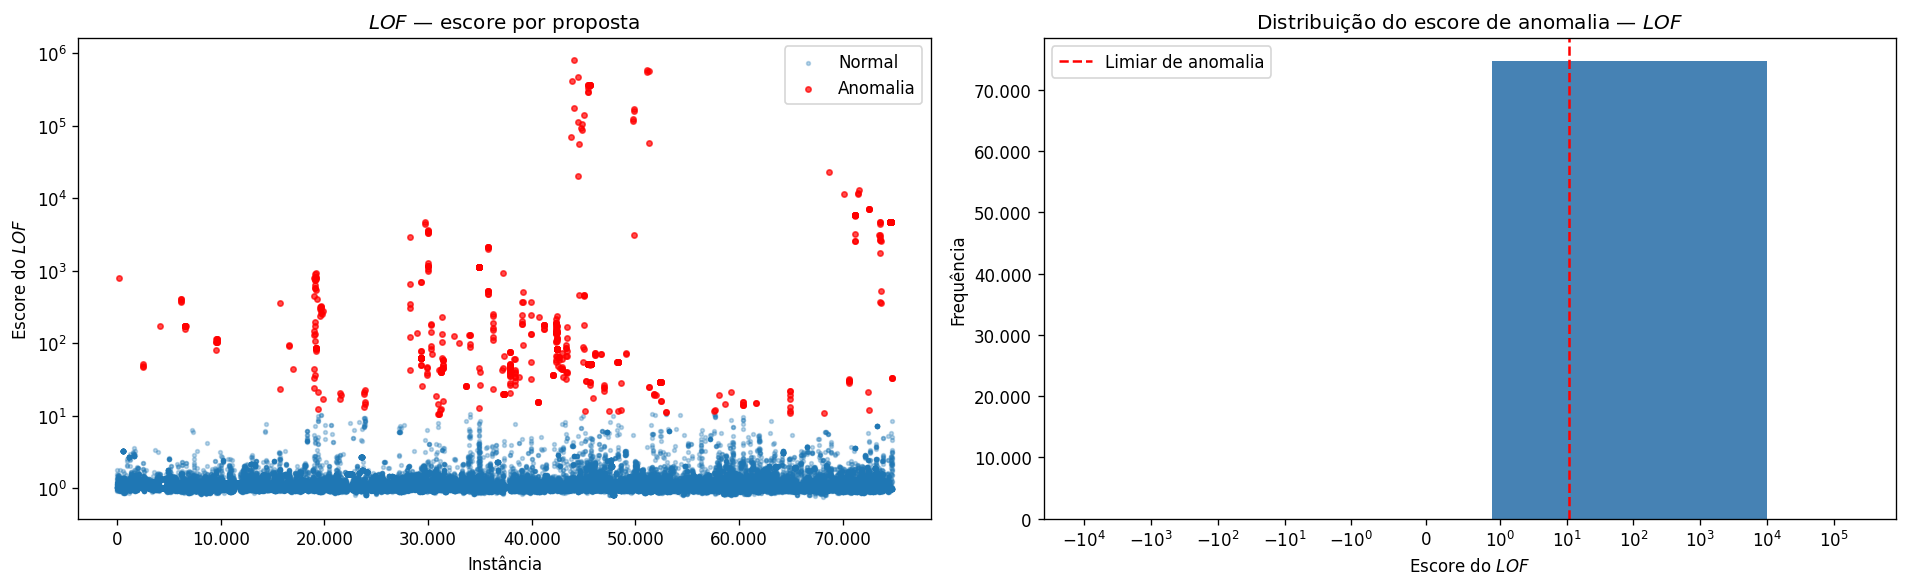

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

normal = df[df['lof_anomaly'] == 1]
anomalies = df[df['lof_anomaly'] == -1]

axes[0].scatter(normal.index, normal['lof_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['lof_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel(r'Escore do $\mathit{LOF}$')
axes[0].set_title(r'$\mathit{LOF}$ — escore por proposta')
axes[0].set_yscale('symlog', linthresh=1)  # escala simétrica-log: evita notação científica (1e14)
axes[0].legend()
fmt_eixo(axes[0], 'x', 0)

axes[1].hist(df['lof_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(df[df['lof_anomaly'] == -1]['lof_anomaly_score'].min(),
                color='red', linestyle='--', label='Limiar de anomalia')
axes[1].set_xlabel(r'Escore do $\mathit{LOF}$')
axes[1].set_ylabel("Frequência")
axes[1].set_title(r'Distribuição do escore de anomalia — $\mathit{LOF}$')
axes[1].set_xscale('symlog', linthresh=1)
axes[1].legend()
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('figuras_tcc/image2.png', dpi=200, bbox_inches='tight')
plt.show()

--- 
### One Class SVM

In [11]:
ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
ocsvm.fit(df[feature_cols])

ocsvm_predictions = ocsvm.predict(df[feature_cols])
ocsvm_scores = ocsvm.decision_function(df[feature_cols])

df['ocsvm_anomaly_score'] = ocsvm_scores
df['ocsvm_anomaly'] = ocsvm_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas: {(df['ocsvm_anomaly'] == -1).sum()} ({(df['ocsvm_anomaly'] == -1).mean():.1%})")
df['ocsvm_anomaly'].value_counts()

Total de propostas: 74755
Anomalias detectadas: 806 (1.1%)


ocsvm_anomaly
 1    73949
-1      806
Name: count, dtype: int64

### Resultados e Visualizações - One Class SVM

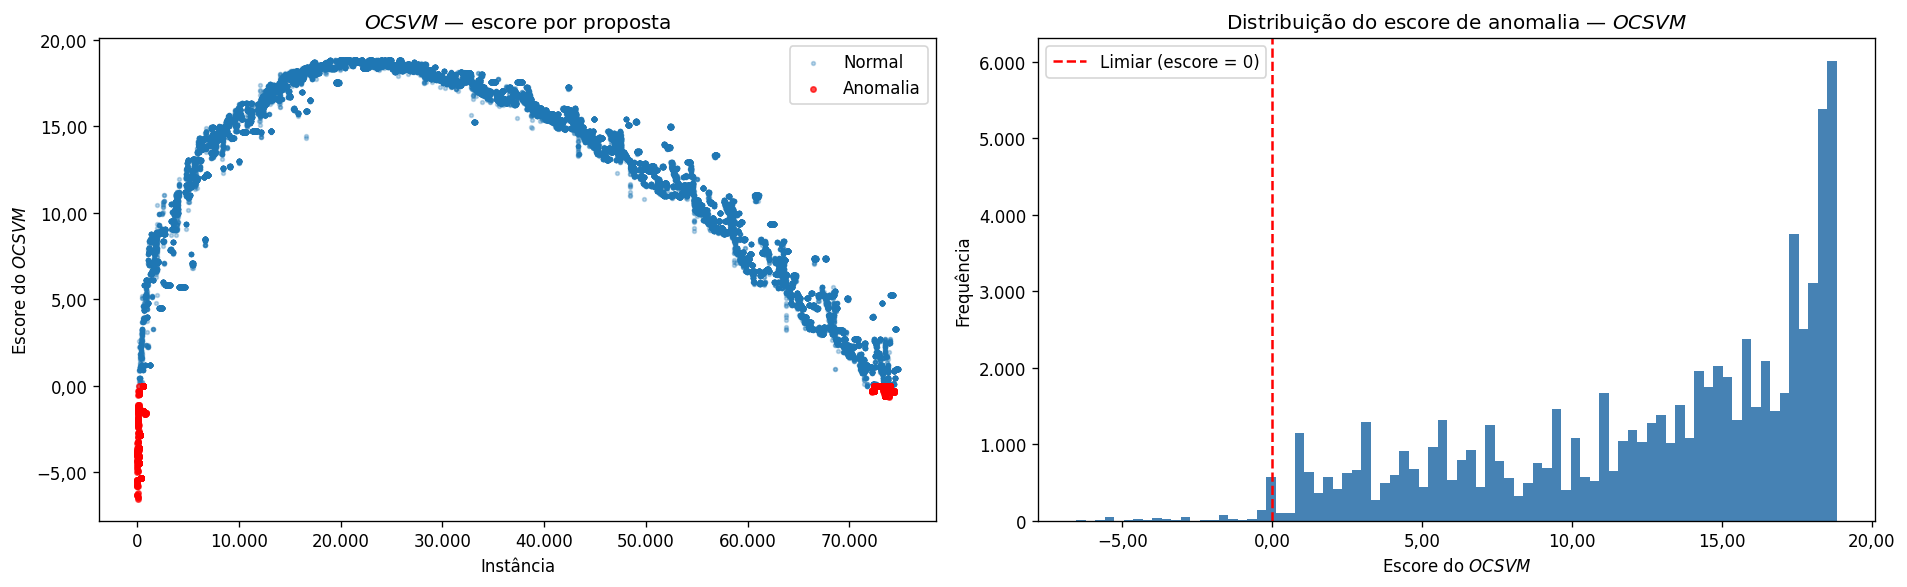

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter: escore × índice
normal = df[df['ocsvm_anomaly'] == 1]
anomalies = df[df['ocsvm_anomaly'] == -1]

axes[0].scatter(normal.index, normal['ocsvm_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['ocsvm_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel(r'Escore do $\mathit{OCSVM}$')
axes[0].set_title(r'$\mathit{OCSVM}$ — escore por proposta')
axes[0].legend()
fmt_eixo(axes[0], 'x', 0)
fmt_eixo(axes[0], 'y', 2)

# Histograma
axes[1].hist(df['ocsvm_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(0, color='red', linestyle='--', label='Limiar (escore = 0)')
axes[1].set_xlabel(r'Escore do $\mathit{OCSVM}$')
axes[1].set_ylabel("Frequência")
axes[1].set_title(r'Distribuição do escore de anomalia — $\mathit{OCSVM}$')
axes[1].legend()
fmt_eixo(axes[1], 'x', 2)
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('figuras_tcc/image14.png', dpi=200, bbox_inches='tight')
plt.show()

### Nomalização das Features - One Class SVM

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_cols])

ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
ocsvm.fit(X_scaled)

ocsvm_predictions = ocsvm.predict(X_scaled)
ocsvm_scores = ocsvm.decision_function(X_scaled)

df['ocsvm_anomaly_score'] = ocsvm_scores
df['ocsvm_anomaly'] = ocsvm_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas (pós normalização): {(df['ocsvm_anomaly'] == -1).sum()} ({(df['ocsvm_anomaly'] == -1).mean():.1%})")
df['ocsvm_anomaly'].value_counts()

Total de propostas: 74755
Anomalias detectadas (pós normalização): 765 (1.0%)


ocsvm_anomaly
 1    73990
-1      765
Name: count, dtype: int64

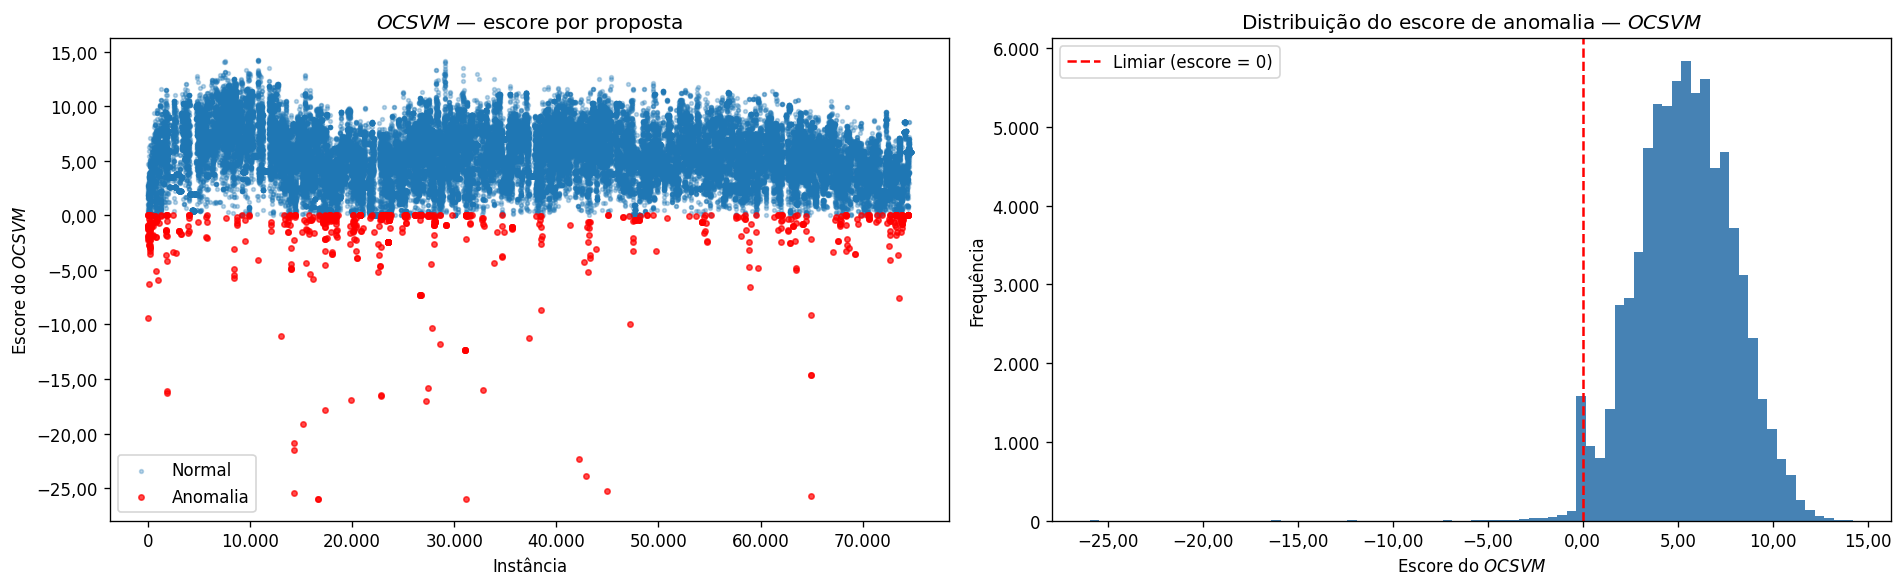

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter: escore × índice
normal = df[df['ocsvm_anomaly'] == 1]
anomalies = df[df['ocsvm_anomaly'] == -1]

axes[0].scatter(normal.index, normal['ocsvm_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['ocsvm_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel(r'Escore do $\mathit{OCSVM}$')
axes[0].set_title(r'$\mathit{OCSVM}$ — escore por proposta')
axes[0].legend()
fmt_eixo(axes[0], 'x', 0)
fmt_eixo(axes[0], 'y', 2)

# Histograma
axes[1].hist(df['ocsvm_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(0, color='red', linestyle='--', label='Limiar (escore = 0)')
axes[1].set_xlabel(r'Escore do $\mathit{OCSVM}$')
axes[1].set_ylabel("Frequência")
axes[1].set_title(r'Distribuição do escore de anomalia — $\mathit{OCSVM}$')
axes[1].legend()
fmt_eixo(axes[1], 'x', 2)
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('figuras_tcc/image11.png', dpi=200, bbox_inches='tight')
plt.show()

---
### Silhouette Score — Qualidade da Separação entre Normal e Anômalo

O **Silhouette Score** mede o quão bem separados estão os dois grupos criados por cada modelo
(normal vs. anomalia) no espaço de features. Varia de **-1 a +1**:

| Faixa | Interpretação |
|---|---|
| Próximo de +1 | Grupos bem separados e compactos |
| Próximo de 0 | Grupos sobrepostos / fronteira difusa |
| Negativo | Pontos mais próximos do outro grupo do que do próprio |

**Procedimento.** O cálculo é O(n²) e a base tem 74.755 registros, então ele é feito sobre uma amostra. Uma amostra aleatória simples de 5.000 registros traz só cerca de 50 anomalias (1%), e o resultado
depende da semente (no LOF, de −0,11 a +0,15 em 30 sementes, teste feito à parte com o procedimento anterior). Por isso a amostra é **estratificada pelo rótulo do modelo** e **repetida**:

1. entram **todas as anomalias** do modelo e **5.000 normais** sorteados (a cada repetição);
2. as features são padronizadas (`StandardScaler`) **na base inteira**, a mesma matriz usada no LOF e no One-Class SVM;
3. o Silhouette é calculado por ponto (`silhouette_samples`) e resumido **por grupo** (anomalias e normais) e **ponderado às proporções da base** (a amostra tem ~13% de anomalias, a base tem 1%);
4. o procedimento é repetido com 30 sementes (0 a 29) e reporta-se média ± desvio-padrão.

**Como interpretar.** O Silhouette usa distância euclidiana *global*: ele favorece grupos compactos e separados. Como 99% dos pontos são normais, o valor ponderado é praticamente o dos normais, e portanto **não mede a qualidade da detecção**
(sem rótulo verdadeiro, nenhuma métrica interna mede). O que informa algo sobre as anomalias é o Silhouette do grupo de anomalias. O LOF, que mede densidade *local*, é penalizado de forma estrutural por essa métrica.


=== Silhouette Score estratificado (todas as anomalias + 5.000 normais; 30 repetições; média ± desvio-padrão) ===
  IF     anomalias −0,0851 ± 0,0014 | normais 0,4287 ± 0,0034 | ponderado à base 0,4235 ± 0,0034 | anomalias na base: 747
  LOF    anomalias 0,0923 ± 0,0025 | normais −0,0098 ± 0,0023 | ponderado à base −0,0087 ± 0,0022 | anomalias na base: 750
  OCSVM  anomalias −0,2064 ± 0,0005 | normais 0,4422 ± 0,0021 | ponderado à base 0,4356 ± 0,0021 | anomalias na base: 765


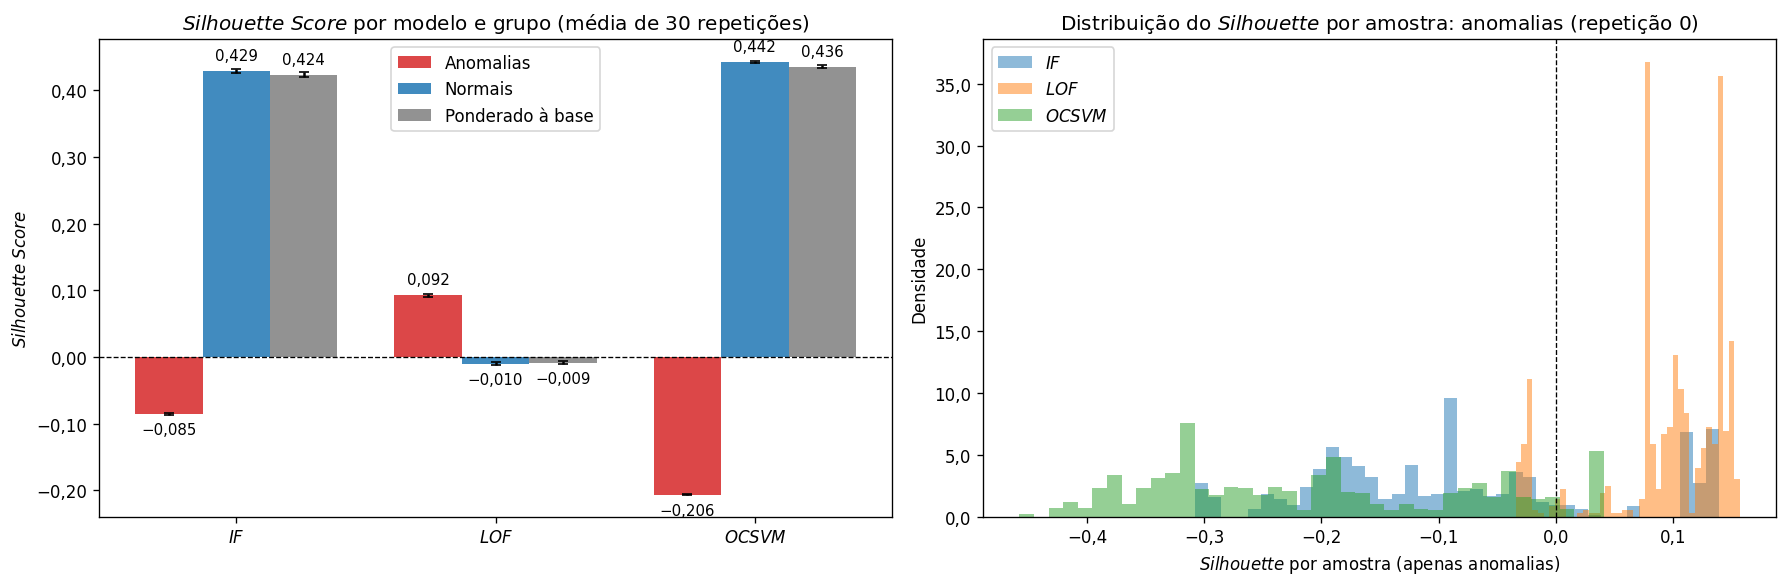

In [15]:
N_NORMAIS = 5000        # normais sorteados a cada repetição (todas as anomalias entram sempre)
N_REPETICOES = 30       # sementes 0 a 29

# Padronização na base inteira (mesma matriz do LOF e do One-Class SVM), não na amostra
X_sil = StandardScaler().fit_transform(df[feature_cols])
rotulos = {'IF': df['anomaly'].to_numpy(), 'LOF': df['lof_anomaly'].to_numpy(), 'OCSVM': df['ocsvm_anomaly'].to_numpy()}


def silhouette_estratificado(semente):
    rng = np.random.RandomState(semente)
    saida = {}
    for nome, rot in rotulos.items():
        anom = np.where(rot == -1)[0]
        norm = np.where(rot == 1)[0]
        ix = np.r_[anom, rng.choice(norm, N_NORMAIS, replace=False)]
        s = silhouette_samples(X_sil[ix], rot[ix])
        eh_anom = rot[ix] == -1
        s_an, s_no = s[eh_anom].mean(), s[~eh_anom].mean()
        saida[nome] = dict(anomalias=s_an, normais=s_no,
                           ponderado=(len(anom) * s_an + len(norm) * s_no) / (len(anom) + len(norm)),    # proporções da base
                           n_anomalias=len(anom), amostras_anom=s[eh_anom])
    return saida


from joblib import Parallel, delayed
rodadas = Parallel(n_jobs=4)(delayed(silhouette_estratificado)(sem) for sem in range(N_REPETICOES))

sil_long = pd.DataFrame([{'semente': sem, 'modelo': nome, **{k: v for k, v in r.items() if k != 'amostras_anom'}}
                         for sem, rod in enumerate(rodadas) for nome, r in rod.items()])
sil_long.to_csv('data/output/silhouette_estratificado.csv', index=False)

resumo = sil_long.groupby('modelo')[['anomalias', 'normais', 'ponderado']].agg(['mean', 'std']).loc[['IF', 'LOF', 'OCSVM']]
print(f'=== Silhouette Score estratificado (todas as anomalias + {br(N_NORMAIS)} normais; {N_REPETICOES} repetições; média ± desvio-padrão) ===')
for nome in ['IF', 'LOF', 'OCSVM']:
    r = resumo.loc[nome]
    print(f"  {nome:6s} anomalias {br(r[('anomalias', 'mean')], 4)} ± {br(r[('anomalias', 'std')], 4)} | "
          f"normais {br(r[('normais', 'mean')], 4)} ± {br(r[('normais', 'std')], 4)} | "
          f"ponderado à base {br(r[('ponderado', 'mean')], 4)} ± {br(r[('ponderado', 'std')], 4)} | anomalias na base: {br(rodadas[0][nome]['n_anomalias'])}")

modelos = [r'$\mathit{IF}$', r'$\mathit{LOF}$', r'$\mathit{OCSVM}$']
nomes   = ['IF', 'LOF', 'OCSVM']
grupos  = [('anomalias', 'Anomalias', '#d62728'), ('normais', 'Normais', '#1f77b4'), ('ponderado', 'Ponderado à base', '#7f7f7f')]
cores   = ['#1f77b4', '#ff7f0e', '#2ca02c']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

larg = 0.26
x = np.arange(len(nomes))
for j, (col, rotulo, cor) in enumerate(grupos):
    medias = [resumo.loc[n][(col, 'mean')] for n in nomes]
    desvios = [resumo.loc[n][(col, 'std')] for n in nomes]
    barras = axes[0].bar(x + (j - 1) * larg, medias, larg, yerr=desvios, capsize=3, color=cor, alpha=0.85, label=rotulo)
    for b, v in zip(barras, medias):
        axes[0].text(b.get_x() + b.get_width() / 2, v + (0.012 if v >= 0 else -0.012), br(v, 3),
                     ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_xticks(x)
axes[0].set_xticklabels(modelos)
axes[0].set_ylabel(r'$\mathit{Silhouette\ Score}$')
axes[0].set_title(r'$\mathit{Silhouette\ Score}$ por modelo e grupo (média de 30 repetições)')
axes[0].legend()
fmt_eixo(axes[0], 'y', 2)

for nome, mod, cor in zip(nomes, modelos, cores):
    axes[1].hist(rodadas[0][nome]['amostras_anom'], bins=40, alpha=0.5, color=cor, label=mod, density=True)
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_xlabel(r'$\mathit{Silhouette}$ por amostra (apenas anomalias)')
axes[1].set_ylabel('Densidade')
axes[1].set_title(r'Distribuição do $\mathit{Silhouette}$ por amostra: anomalias (repetição 0)')
axes[1].legend()
fmt_eixo(axes[1], 'x', 1)
fmt_eixo(axes[1], 'y', 1)

plt.tight_layout()
plt.savefig('figuras_tcc/image10.png', dpi=200, bbox_inches='tight')
plt.show()


**Leitura (rodada atual).**
- **O valor ponderado é o dos normais**: IF +0,424 e OCSVM +0,436 ponderados contra +0,429 e +0,442 nos normais, porque 99% da base é normal. Não é uma medida da qualidade da detecção.
- **O grupo de anomalias é o que informa**: **−0,085 (IF)**, **+0,092 (LOF)** e **−0,206 (OCSVM)**. No IF e no OCSVM, as anomalias ficam em média mais perto do núcleo de normais do que umas das outras. Isso é esperado em modelos que sinalizam pontos nas bordas (por isolamento e por fronteira): esses pontos são dispersos e não formam um grupo compacto, o que não indica erro do modelo. O valor positivo do LOF mostra grupos de densidade local mais coesos.
- **LOF próximo de zero no valor ponderado (−0,009)**: o LOF mede densidade *local* e o Silhouette mede distância *global*; um ponto pode ser anômalo em densidade sem estar longe do restante em distância euclidiana. O valor próximo de zero reflete essa diferença de critério (ver também NB09, seção 2.4).
- **Sensível a duplicatas**: as anomalias têm cópias idênticas (NB09, seção 2.5), e cópias têm distância zero entre si, o que aproxima os pontos do mesmo grupo. Na versão anterior à correção do *join* do cadastro (com 770 linhas repetidas), o grupo de anomalias do IF tinha +0,107 e o do OCSVM, −0,181. O valor deste grupo deve ser lido com essa ressalva.
- **O procedimento é estável**: o desvio-padrão entre as 30 repetições é de no máximo 0,0034, de modo que a comparação entre modelos não depende da semente.
- **Limitação:** o Silhouette mede separação geométrica, não acerto. Sem rótulo verdadeiro, ele serve para comparar a forma dos grupos, não para escolher o melhor modelo; por isso o ranking combinado (NB09) usa os três modelos e não um deles.
